In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [3]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.isnull().sum()
df.head()


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)
numerical_columns = list(df.dtypes[df.dtypes != 'object'].index)
for col in categorical_columns:
    df[col] = df[col].fillna('N/A')
for col in numerical_columns:
    df[col] = df[col].fillna(0.0)


df.isnull().sum()



lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)


(3000, 1000, 1000)

In [6]:
from sklearn.model_selection import train_test_split

print(categorical_columns)
print(numerical_columns)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']

print(len(df_train), len(df_val), len(df_test))

[]
['lead_source', 'industry', 'employment_status', 'location', 'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']
3000 1000 1000


In [7]:
featue_columns = categorical_columns + numerical_columns
dv = DictVectorizer(sparse=False)
feature_columns = df_train.columns.tolist()  # excludes the target
dv = DictVectorizer(sparse=False)

train_dict = df_train[feature_columns].to_dict(orient='records')
val_dict = df_val[feature_columns].to_dict(orient='records')

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

for col in ['lead_score', 'number_of_courses_viewed',
            'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[col])
    print(col, auc)


lead_score 0.7882254810906102
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
annual_income 0.6081977776250831


Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

lead_score has the highest AUC score 0.7882254810906102

### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [8]:
dv = DictVectorizer(sparse=False)
feature_columns = [col for col in df_train.columns if col != 'converted']
train_dict = df_train[feature_columns].to_dict(orient='records')
val_dict = df_val[feature_columns].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

In [9]:
model = LogisticRegression(solver='liblinear', random_state=1)
model.fit(X_train, y_train)
y_pred_prob = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred_prob)
print('Validation AUC:', round(auc, 3))

Validation AUC: 0.732


Response = 0.732

### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

In [10]:
from sklearn.metrics import precision_score, recall_score

In [11]:
X_val = dv.transform(df_val.to_dict(orient='records'))
y_pred_prob = model.predict_proba(X_val)[:, 1]
thresholds = []
for t in np.arange(0.00, 1.01, 0.01):
    y_pred_t = (y_pred_prob >= t).astype(int)
    p = precision_score(y_val, y_pred_t, zero_division=0)
    r = recall_score(y_val, y_pred_t, zero_division=0)
    thresholds.append((t, p, r))


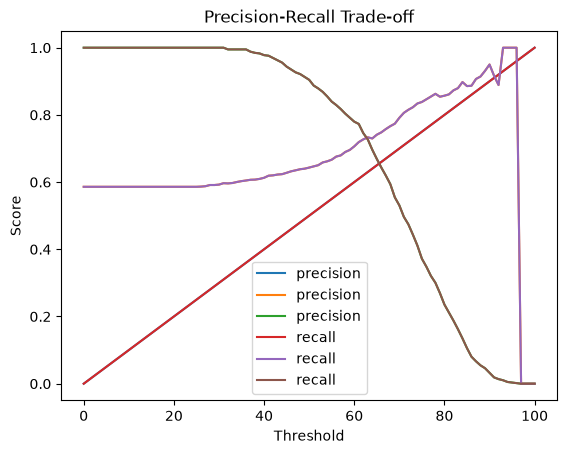

In [12]:
plt.plot(thresholds, label='precision')
plt.plot(thresholds, label='recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off')
plt.legend()
plt.show()

In [13]:
candidats = [x for x in thresholds if not (x[1] == 0 and x[2] == 0)]
meilleur = min(candidats, key=lambda x: abs(x[1] - x[2]))
print(f"seuil = {meilleur[0]:.2f}")
print(f", precision = {meilleur[1]:.3f}")
print(f", recall = {meilleur[2]:.4f}")
print(f"|P-R| = {abs(meilleur[1] - meilleur[2]):.6f}")

seuil = 0.63
, precision = 0.733
, recall = 0.7270
|P-R| = 0.006256


In [14]:
print("\nvoinage :")
for t, p, r in candidats:
    if abs(t - meilleur[0]) <= 0.04:
        print(f" t = {t:.2f}, P = {p:.4f}, R = {r:.4f}, diff = {abs(p - r):.4f}")


voinage :
 t = 0.60, P = 0.7063, R = 0.7799, diff = 0.0735
 t = 0.61, P = 0.7190, R = 0.7730, diff = 0.0540
 t = 0.62, P = 0.7271, R = 0.7457, diff = 0.0186
 t = 0.63, P = 0.7332, R = 0.7270, diff = 0.0063
 t = 0.64, P = 0.7299, R = 0.6962, diff = 0.0336
 t = 0.65, P = 0.7410, R = 0.6689, diff = 0.0721
 t = 0.66, P = 0.7480, R = 0.6433, diff = 0.1047


Response 3 : precision and recall curves intersect at threshold 0.63

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [18]:
from sklearn.metrics import f1_score

f1_values = []
for t in np.arange(0.00, 1.01, 0.01):
    y_pred_t = (y_pred_prob >= t).astype(int)
    f1_values.append((t, f1_score(y_val, y_pred_t, zero_division=0)))

best_f1 = max(f1_values, key=lambda x: x[1])
print(f"seuil = {best_f1[0]:.2f}, F1 = {best_f1[1]:.4f}")

print("\nvoisinage :")
for t, f in f1_values:
    if abs(t - best_f1[0]) <= 0.04:
        print(f"  t={t:.2f}  F1={f:.4f}")

seuil = 0.41, F1 = 0.7576

voisinage :
  t=0.38  F1=0.7513
  t=0.39  F1=0.7524
  t=0.40  F1=0.7535
  t=0.41  F1=0.7576
  t=0.42  F1=0.7563
  t=0.43  F1=0.7560
  t=0.44  F1=0.7547
  t=0.45  F1=0.7539


Response 4: 0.41

### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [15]:
from sklearn.model_selection import KFold

In [16]:
df_cv = df_full_train.reset_index(drop=True)
y_cv  = df_cv['converted'].values
X_cv  = df_cv.drop(columns=['converted'])

kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_index, val_index in kf.split(X_cv):
    Xa, Xb = X_cv.iloc[train_index], X_cv.iloc[val_index]
    ya, yb = y_cv[train_index], y_cv[val_index]

    dv_fold = DictVectorizer(sparse=False)
    A = dv_fold.fit_transform(Xa.to_dict(orient='records'))
    B = dv_fold.transform(Xb.to_dict(orient='records'))

    m = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    m.fit(A, ya)
    scores.append(roc_auc_score(yb, m.predict_proba(B)[:, 1]))

print("scores :", [round(s, 4) for s in scores])
print("mean   :", round(np.mean(scores), 4))
print("std    :", round(np.std(scores), 3))

scores : [0.7305, 0.7297, 0.7363, 0.7413, 0.721]
mean   : 0.7318
std    : 0.007


Response : std = 0.007

### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [17]:
results = {}

for C in [0.000001, 0.001, 1]:
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    sc = []

    for train_index, val_index in kf.split(X_cv):
        Xa, Xb = X_cv.iloc[train_index], X_cv.iloc[val_index]
        ya, yb = y_cv[train_index], y_cv[val_index]

        dv_fold = DictVectorizer(sparse=False)
        A = dv_fold.fit_transform(Xa.to_dict(orient='records'))
        B = dv_fold.transform(Xb.to_dict(orient='records'))

        m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        m.fit(A, ya)
        sc.append(roc_auc_score(yb, m.predict_proba(B)[:, 1]))

    results[C] = (round(float(np.mean(sc)), 3), round(float(np.std(sc)), 3))
    print(f"C={C:<10} mean={results[C][0]}  std={results[C][1]}")


C=1e-06      mean=0.617  std=0.019
C=0.001      mean=0.749  std=0.01
C=1          mean=0.732  std=0.007


Best C is 0.001